# Computer Vision Final Project
## Efficient Image Clustering using SIFT + CNN (Ensemble)




In [ ]:
# (Colab) Install dependencies
!pip -q install opencv-contrib-python scikit-learn numpy tensorflow matplotlib

In [ ]:
import os, random, shutil
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Mount Drive (Colab)
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1) Build a Caltech101 subset

In [ ]:
 # Path to your full Caltech101 dataset in Drive
full_dataset_dir = "/content/drive/MyDrive/caltech-101"
# Path to store subset
subset_dir = "/content/drive/MyDrive/Caltech101_subset"
os.makedirs(subset_dir, exist_ok=True)

# DO NOT set random seed → true randomness
categories = [c for c in os.listdir(full_dataset_dir)
              if os.path.isdir(os.path.join(full_dataset_dir, c))]
print("Total categories:", len(categories))

n_classes = 10
max_imgs_per_class = 50

selected_classes = random.sample(categories, n_classes)
print("Selected classes:", selected_classes)

for cat in selected_classes:
    dst_cat = os.path.join(subset_dir, cat)
    os.makedirs(dst_cat, exist_ok=True)

    src_cat = os.path.join(full_dataset_dir, cat)
    files = [f for f in os.listdir(src_cat)
             if os.path.isfile(os.path.join(src_cat, f))]

    chosen_files = random.sample(files, min(len(files), max_imgs_per_class))
    for f in chosen_files:
        shutil.copy(os.path.join(src_cat, f), os.path.join(dst_cat, f))

print("Subset created at:", subset_dir)

Total categories: 102
Selected classes: ['dolphin', 'minaret', 'trilobite', 'lamp', 'water_lilly', 'panda', 'wheelchair', 'buddha', 'crocodile', 'ceiling_fan']
Subset created at: /content/drive/MyDrive/Caltech101_subset


## 2) Preview sample images

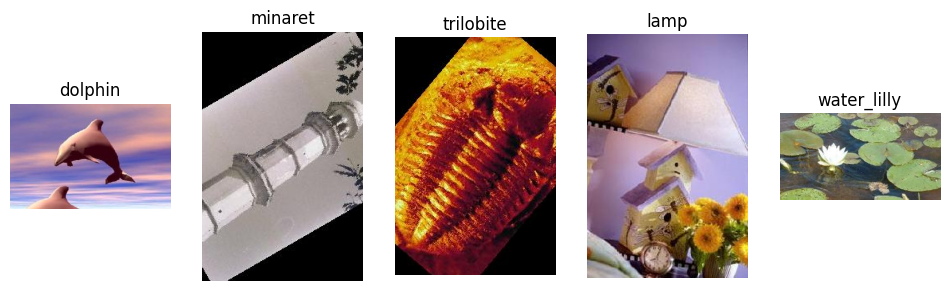

In [ ]:
import matplotlib.image as mpimg

fig = plt.figure(figsize=(12, 4))
for i, cat in enumerate(selected_classes[:5], start=1):
    img_path = os.path.join(subset_dir, cat, os.listdir(os.path.join(subset_dir, cat))[0])
    img = mpimg.imread(img_path)
    ax = fig.add_subplot(1, 5, i)
    ax.imshow(img)
    ax.set_title(cat)
    ax.axis("off")
plt.show()

## 3) Collect image paths and labels (shared by all pipelines)

In [ ]:
all_img_paths = []
all_labels = []

for cat in selected_classes:
    cat_dir = os.path.join(subset_dir, cat)
    for f in os.listdir(cat_dir):
        p = os.path.join(cat_dir, f)
        if os.path.isfile(p):
            all_img_paths.append(p)
            all_labels.append(cat)

print("Total images:", len(all_img_paths))

Total images: 604


## 4) SIFT feature extraction (fixed, stable vector length)

Here we build a **Bag of Visual Words (BoVW)** representation:
- Extract SIFT descriptors per image
- Fit MiniBatchKMeans to form a visual vocabulary
- Represent each image as a histogram of visual words

In [ ]:
import cv2
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import normalize

sift = cv2.SIFT_create()

def extract_sift_desc(img_path):
    img = cv2.imread(img_path)
    if img is None:
        return None
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    kp, des = sift.detectAndCompute(gray, None)
    return des  # (n_kp, 128) or None

# 1) collect descriptors
all_des = []
per_img_des = []

for p in all_img_paths:
    des = extract_sift_desc(p)
    per_img_des.append(des)
    if des is not None and len(des) > 0:
        all_des.append(des)

all_des = np.vstack(all_des) if len(all_des) else None
print("Total SIFT descriptors:", None if all_des is None else all_des.shape)

Total SIFT descriptors: (257847, 128)


In [ ]:
# 2) build vocabulary + histograms
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

vocab_size = 200  # you can tune: 100, 200, 400
if all_des is None:
    raise RuntimeError("No SIFT descriptors found. Check images / OpenCV installation.")

kmeans_vocab = MiniBatchKMeans(n_clusters=vocab_size, random_state=42, batch_size=4096)
kmeans_vocab.fit(all_des)

def bovw_hist(des):
    if des is None or len(des) == 0:
        return np.zeros(vocab_size, dtype=np.float32)
    words = kmeans_vocab.predict(des)
    h, _ = np.histogram(words, bins=np.arange(vocab_size+1))
    return h.astype(np.float32)

X_sift = np.vstack([bovw_hist(d) for d in per_img_des])
X_sift = normalize(X_sift, norm="l1")  # histogram normalization

print("BoVW SIFT feature matrix:", X_sift.shape)

# Optional PCA for compactness
pca_sift = PCA(n_components=50, random_state=42)
X_sift_pca = pca_sift.fit_transform(X_sift)

scaler_sift = StandardScaler()
X_sift_scaled = scaler_sift.fit_transform(X_sift_pca)

print("SIFT after PCA:", X_sift_scaled.shape)

BoVW SIFT feature matrix: (604, 200)
SIFT after PCA: (604, 50)


## 5) CNN feature extraction (MobileNetV2) + image-path tracking

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import img_to_array, load_img
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from PIL import UnidentifiedImageError

cnn_model = MobileNetV2(weights="imagenet", include_top=False, pooling="avg")

def load_preprocess(img_path, size=(224,224)):
    try:
        img = load_img(img_path, target_size=size)
        arr = img_to_array(img)
        arr = preprocess_input(arr)
        return arr
    except (UnidentifiedImageError, FileNotFoundError) as e:
        print(f"Warning: Could not load image {img_path} due to: {e}. Skipping this image.")
        return None

batch_size = 32
cnn_features = []
cnn_paths = []
cnn_labels = []

batch_imgs = []
batch_paths = []
batch_labels = []

for p, lab in zip(all_img_paths, all_labels):
    processed_img = load_preprocess(p)
    if processed_img is not None:
        batch_imgs.append(processed_img)
        batch_paths.append(p)
        batch_labels.append(lab)
    if len(batch_imgs) == batch_size:
        feats = cnn_model.predict(np.array(batch_imgs), verbose=0)
        cnn_features.extend(feats)
        cnn_paths.extend(batch_paths)
        cnn_labels.extend(batch_labels)
        batch_imgs, batch_paths, batch_labels = [], [], []

if batch_imgs:
    feats = cnn_model.predict(np.array(batch_imgs), verbose=0)
    cnn_features.extend(feats)
    cnn_paths.extend(batch_paths)
    cnn_labels.extend(batch_labels)

cnn_features = np.array(cnn_features)
print("CNN features:", cnn_features.shape)
print("CNN paths match:", len(cnn_paths) == len(cnn_features))

/tmp/ipython-input-3105066815.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  cnn_model = MobileNetV2(weights="imagenet", include_top=False, pooling="avg")


CNN features: (604, 1280)
CNN paths match: True


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(all_labels)  # ground-truth labels (for evaluation only)

# Scale CNN features
from sklearn.preprocessing import StandardScaler
scaler_cnn = StandardScaler()
X_cnn_scaled = scaler_cnn.fit_transform(cnn_features)

print("Label classes:", list(le.classes_))
print("y shape:", y.shape)

Label classes: [np.str_('buddha'), np.str_('ceiling_fan'), np.str_('crocodile'), np.str_('dolphin'), np.str_('lamp'), np.str_('minaret'), np.str_('panda'), np.str_('trilobite'), np.str_('water_lilly'), np.str_('wheelchair')]
y shape: (604,)


## 6) Feature fusion (SIFT + CNN)
Early fusion by averaging and weighted scaled SIFT-PCA and scaled CNN features.

In [ ]:
# 2) Fusion Strategy 2: Feature Averaging
from sklearn.decomposition import PCA
pca_cnn = PCA(n_components=X_sift_scaled.shape[1], random_state=42)
X_cnn_pca = pca_cnn.fit_transform(X_cnn_scaled)

In [ ]:
# Average fusion
X_fused_avg = 0.5 * (X_sift_scaled + X_cnn_pca)
print("Fused features (Averaging):", X_fused_avg.shape)

Fused features (Averaging): (604, 50)


In [ ]:
alpha = 0.8  # Give more weight to CNN features
X_fused_weighted = alpha * X_cnn_pca + (1 - alpha) * X_sift_scaled
print("Fused features (Weighted):", X_fused_weighted.shape)

Fused features (Weighted): (604, 50)


#Alternative methods

1) Power / Gamma Fusion

In [ ]:
gamma = 0.8

# Calculate shift value to handle negative numbers in power transformation
min_sift = np.min(X_sift_scaled)
min_cnn = np.min(X_cnn_pca)
min_overall = min(min_sift, min_cnn)
shift_val = 0.0 # Default to 0 if no negative values
if min_overall < 0:
    shift_val = abs(min_overall) + 1e-6 # Add a small epsilon for strict positivity

X_fuse_power = ((X_sift_scaled + shift_val) ** gamma) * ((X_cnn_pca + shift_val) ** (1 - gamma))
print("Power/Gamma fusion:", X_fuse_power.shape)

Power/Gamma fusion: (604, 50)


2) Log Fusion

In [ ]:
# Calculate shift value for log transformation
min_sift = np.min(X_sift_scaled)
min_cnn = np.min(X_cnn_pca)
min_overall = min(min_sift, min_cnn)
shift_val_log = 0.0
if min_overall <= 0:
    shift_val_log = abs(min_overall) + 1e-6 # Add a small epsilon for strict positivity before log1p(1+x) makes it log(1+x_shifted)

X_fuse_log = np.log1p(X_sift_scaled + shift_val_log) + np.log1p(X_cnn_pca + shift_val_log)
print("Log fusion:", X_fuse_log.shape)

Log fusion: (604, 50)


3.Exponential (Softmax-like) Fusion

In [ ]:
beta = 2.0
X_fuse_exp = np.exp(beta * (X_sift_scaled + X_cnn_pca))
print("Exponential fusion:", X_fuse_exp.shape)

Exponential fusion: (604, 50)


4) Geometric Mean Fusion

In [ ]:
# Define eps (epsilon) for numerical stability
eps = 1e-9

# Calculate shift value for geometric mean to ensure non-negative inputs
min_sift = np.min(X_sift_scaled)
min_cnn = np.min(X_cnn_pca)
min_overall = min(min_sift, min_cnn)
shift_val_gmean = 0.0
if min_overall <= 0:
    shift_val_gmean = abs(min_overall) + 1e-6 # Add a small epsilon for strict positivity

# Apply shift before multiplication for geometric mean
X_fuse_gmean = np.sqrt((X_sift_scaled + shift_val_gmean) * (X_cnn_pca + shift_val_gmean) + eps)
print("Geometric-mean fusion:", X_fuse_gmean.shape)

Geometric-mean fusion: (604, 50)


# Fusion Strategy 3: Weighted Feature Fusion

## 7) Clustering (K-Means) + Evaluation
Metrics:
- **Silhouette score** (unsupervised)
- **ARI / NMI** (uses true labels only for reporting)

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

def cluster_and_report(X, name, n_clusters):
    km = KMeans(n_clusters=n_clusters, random_state=42, n_init="auto")
    pred = km.fit_predict(X)
    sil = silhouette_score(X, pred)
    ari = adjusted_rand_score(y, pred)
    nmi = normalized_mutual_info_score(y, pred)
    print(f"=== {name} ===")
    print("Silhouette:", round(sil, 4))
    print("ARI:", round(ari, 4))
    print("NMI:", round(nmi, 4))
    return pred

In [ ]:
k = len(selected_classes)
pred_sift = cluster_and_report(X_sift_scaled, "SIFT (BoVW + PCA)", k)
pred_cnn  = cluster_and_report(X_cnn_scaled,  "CNN (MobileNetV2)", k)
pred_fuse = cluster_and_report(X_fused_weighted,  "Fused (SIFT + CNN)", k)

=== SIFT (BoVW + PCA) ===
Silhouette: -0.0122
ARI: 0.0378
NMI: 0.0946
=== CNN (MobileNetV2) ===
Silhouette: 0.0756
ARI: 0.7827
NMI: 0.8941
=== Fused (SIFT + CNN) ===
Silhouette: 0.1911
ARI: 0.8801
NMI: 0.9401


In [ ]:
k = len(selected_classes)
pred_sift = cluster_and_report(X_sift_scaled, "SIFT (BoVW + PCA)", k)
pred_cnn  = cluster_and_report(X_cnn_scaled,  "CNN (MobileNetV2)", k)
pred_fuse = cluster_and_report(X_fused_avg,  "Fused (SIFT + CNN)", k)

=== SIFT (BoVW + PCA) ===
Silhouette: -0.0122
ARI: 0.0378
NMI: 0.0946
=== CNN (MobileNetV2) ===
Silhouette: 0.0756
ARI: 0.7827
NMI: 0.8941
=== Fused (SIFT + CNN) ===
Silhouette: 0.1702
ARI: 0.91
NMI: 0.9513


In [ ]:
k = len(selected_classes)
pred_power = cluster_and_report(X_fuse_power, "Fusion (Power/Gamma)", k)
pred_log   = cluster_and_report(X_fuse_log,   "Fusion (Log)", k)

# Scale X_fuse_exp before clustering to avoid issues with KMeans and silhouette_score
scaler_exp = StandardScaler()
X_fuse_exp_scaled = scaler_exp.fit_transform(X_fuse_exp)
pred_exp   = cluster_and_report(X_fuse_exp_scaled,   "Fusion (Exp) (Scaled)", k)

# Scale X_fuse_gmean before clustering
scaler_gmean = StandardScaler()
X_fuse_gmean_scaled = scaler_gmean.fit_transform(X_fuse_gmean)
pred_gmean = cluster_and_report(X_fuse_gmean_scaled, "Fusion (Geometric Mean) (Scaled)", k)

=== Fusion (Power/Gamma) ===
Silhouette: 0.1205
ARI: 0.864
NMI: 0.9261
=== Fusion (Log) ===
Silhouette: 0.1552
ARI: 0.7712
NMI: 0.888
=== Fusion (Exp) (Scaled) ===
Silhouette: 0.8377
ARI: 0.0012
NMI: 0.0307
=== Fusion (Geometric Mean) (Scaled) ===
Silhouette: 0.0246
ARI: 0.2957
NMI: 0.5746


## 8) PCA 2D visualization of clusters

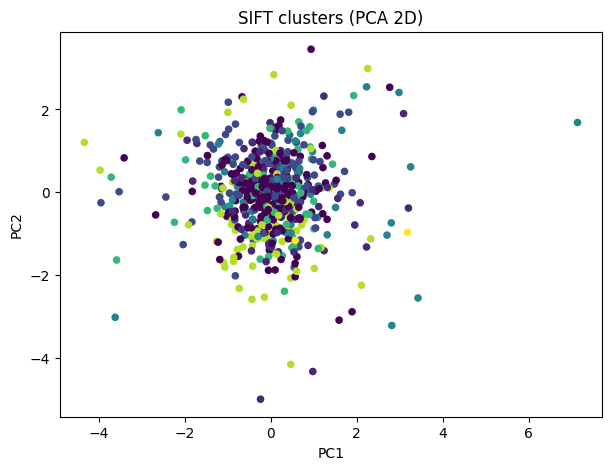

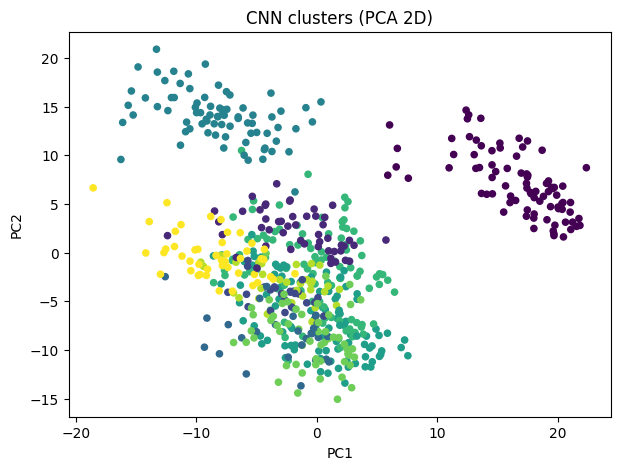

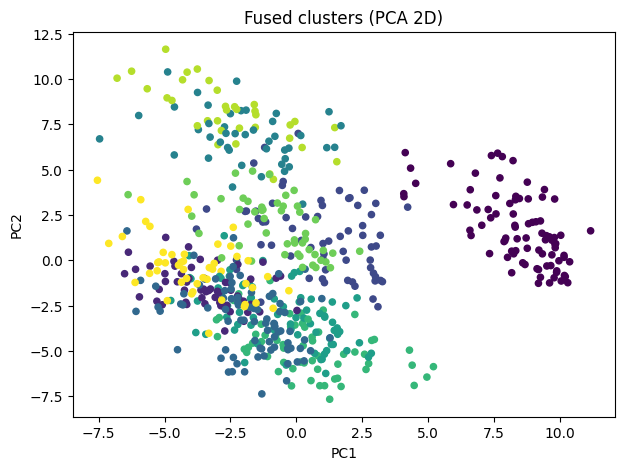

In [ ]:
from sklearn.decomposition import PCA

def pca_plot(X, cluster_ids, title):
    p = PCA(n_components=2, random_state=42)
    Z = p.fit_transform(X)
    plt.figure(figsize=(7,5))
    plt.scatter(Z[:,0], Z[:,1], c=cluster_ids, s=20)
    plt.title(title)
    plt.xlabel("PC1"); plt.ylabel("PC2")
    plt.show()

pca_plot(X_sift_scaled, pred_sift, "SIFT clusters (PCA 2D)")
pca_plot(X_cnn_scaled,  pred_cnn,  "CNN clusters (PCA 2D)")
pca_plot(X_fused_avg,       pred_fuse, "Fused clusters (PCA 2D)")

Displaying samples from 10 clusters (Fused features):

--- Cluster 0 ---
Dominant true labels in cluster 0: ['trilobite']...


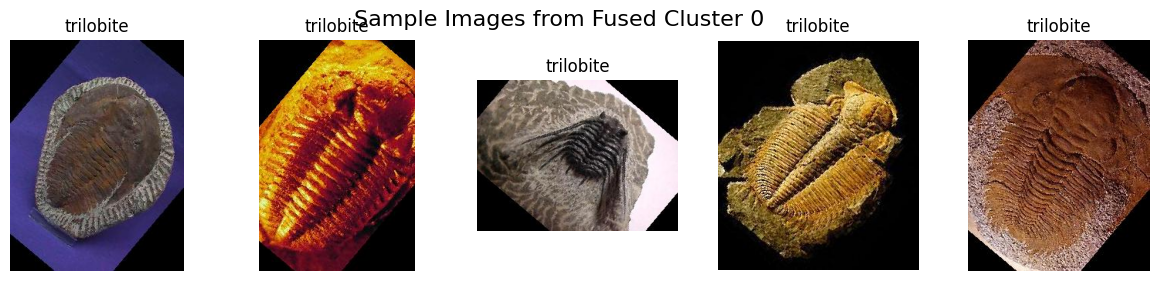


--- Cluster 1 ---
Dominant true labels in cluster 1: ['wheelchair']...


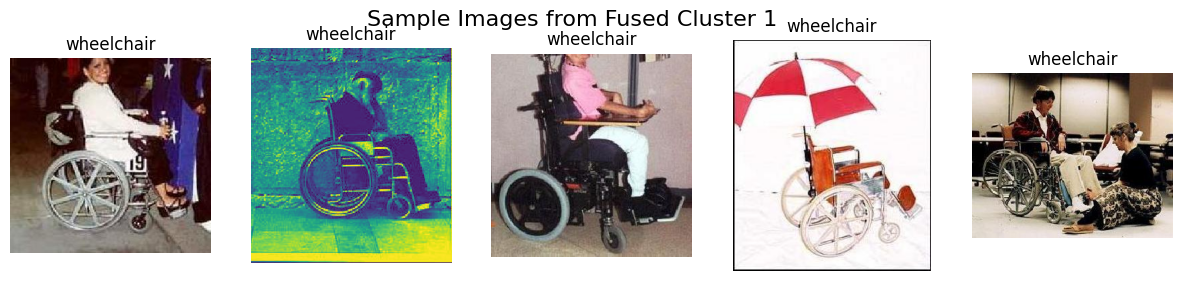


--- Cluster 2 ---
Dominant true labels in cluster 2: ['dolphin']...


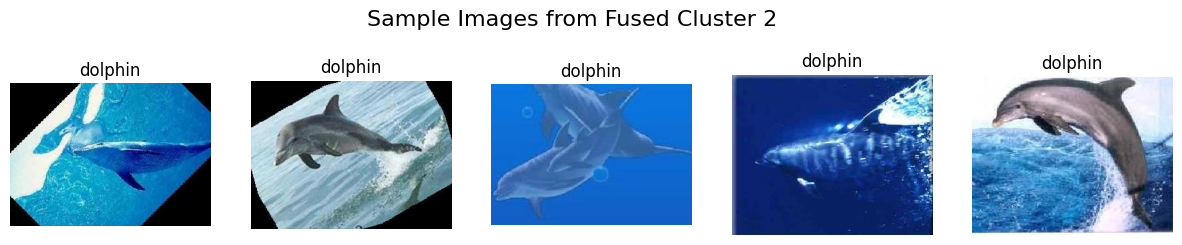


--- Cluster 3 ---
Dominant true labels in cluster 3: ['buddha']...


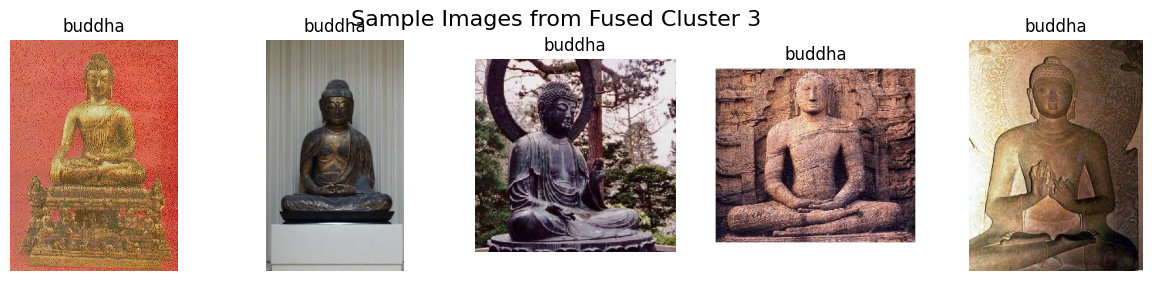

In [ ]:
import random
import matplotlib.image as mpimg

# Using the best performing clustering (Fused features)
cluster_assignments = pred_fuse

# Map cluster IDs back to image paths and true labels
cluster_to_paths = {i: [] for i in range(k)}
cluster_to_labels = {i: [] for i in range(k)}

for i, cluster_id in enumerate(cluster_assignments):
    cluster_to_paths[cluster_id].append(all_img_paths[i])
    cluster_to_labels[cluster_id].append(all_labels[i])

print(f"Displaying samples from {k} clusters (Fused features):")

# Select 4 clusters to visualize (you can change these IDs)
clusters_to_visualize = [0, 1, 2, 3]

for cluster_id in clusters_to_visualize:
    print(f"\n--- Cluster {cluster_id} ---")
    if cluster_id not in cluster_to_paths or not cluster_to_paths[cluster_id]:
        print(f"No images found for cluster {cluster_id}.")
        continue

    # Get unique true labels within this cluster
    unique_labels = list(set(cluster_to_labels[cluster_id]))
    print(f"Dominant true labels in cluster {cluster_id}: {unique_labels[:5]}...") # Show up to 5 dominant labels

    # Display up to 5 random images from the cluster
    sample_images = random.sample(cluster_to_paths[cluster_id], min(5, len(cluster_to_paths[cluster_id])))

    fig = plt.figure(figsize=(15, 3))
    for i, img_path in enumerate(sample_images):
        try:
            img = mpimg.imread(img_path)
            ax = fig.add_subplot(1, min(5, len(sample_images)), i + 1)
            ax.imshow(img)
            ax.set_title(os.path.basename(os.path.dirname(img_path)))
            ax.axis("off")
        except Exception as e:
            print(f"Could not load image {img_path}: {e}")

    plt.suptitle(f"Sample Images from Fused Cluster {cluster_id}", fontsize=16)
    plt.show()


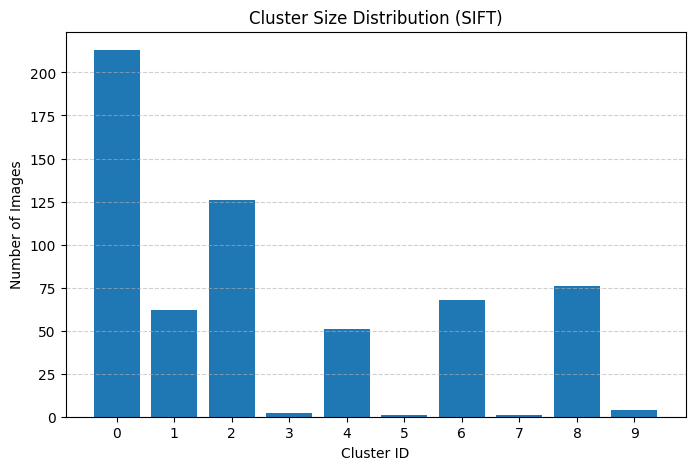

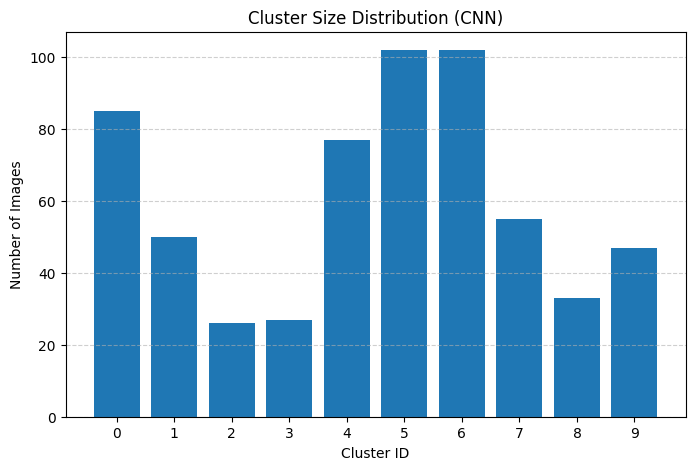

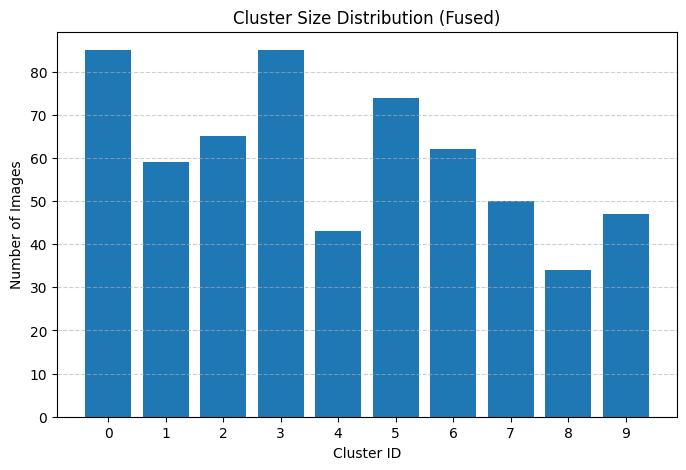

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_cluster_sizes(cluster_labels, title):
    unique, counts = np.unique(cluster_labels, return_counts=True)

    plt.figure(figsize=(8, 5))
    plt.bar(unique, counts)
    plt.xlabel("Cluster ID")
    plt.ylabel("Number of Images")
    plt.title(title)
    plt.xticks(unique)
    plt.grid(axis="y", linestyle="--", alpha=0.6)
    plt.show()

# Example usage:
plot_cluster_sizes(pred_sift, "Cluster Size Distribution (SIFT)")
plot_cluster_sizes(pred_cnn, "Cluster Size Distribution (CNN)")
plot_cluster_sizes(pred_fuse, "Cluster Size Distribution (Fused)")
